# 1. 데이터 추출

## 0. 환경 검증

In [65]:
import shutil
import sys

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
print()

# OS 패키지 확인 (pip로 설치되지 않는 것들)
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
print()

# 파이썬 패키지 확인
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: ✗ 미설치")

Python: 3.11.9
가상환경 경로: c:\workspaces\multimodal-rag\.venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain     : OK
unstructured  : OK
chromadb      : OK
tiktoken      : OK
PIL           : OK


## 1. 라이브러리 임포트


In [66]:
import os
import time
import pickle
from pathlib import Path

from langchain_text_splitters import CharacterTextSplitter
from unstructured.partition.pdf import partition_pdf

print("임포트 완료")

임포트 완료


## 2. 경로 설정

In [67]:
# 경로 기준: 프로젝트 루트 하나 + 데이터 폴더 하나 (이후 모든 셀이 이 두 변수를 사용)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "notebooks" / "data"      # PDF / figures / processed 모두 여기

# TODO 1: 본인의 PDF 파일 이름으로 바꾸세요 (예: "invest.pdf")
fname = "SK_networks.pdf"

fpath = str(DATA_DIR) + os.sep

print("프로젝트 루트:", PROJECT_ROOT)
print("PDF 폴더     :", fpath)
print("PDF 존재 여부:", os.path.exists(fpath + fname))

프로젝트 루트: c:\workspaces\multimodal-rag
PDF 폴더     : c:\workspaces\multimodal-rag\notebooks\data\
PDF 존재 여부: True


## 3. 추출 함수 만들기

| 옵션 | 하는 일 | 빼면 생기는 일 |
| --- | --- | --- |
| `strategy` | 레이아웃 분석 모델로 정밀 추출 | 표·이미지 추출 정확도 급락 |
| `extract_images_in_pdf` | 그림을 별도 파일로 저장 | 이미지가 통째로 사라짐 |
| `infer_table_structure` | 표의 행·열 구조를 추론 | 표가 줄글로 뭉개짐 |

In [68]:
def extract_pdf_elements(path, fname):
    """
    PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다.

    path : 파일 경로 (추출된 이미지 파일이 저장될 위치)
    fname: 파일 이름
    """
    return partition_pdf(
        filename=path + fname,
        languages=["kor", "eng"],           # 한국어+영어 OCR (미지정 시 영어만 → 글자 깨짐)
        strategy="hi_res",                  # TODO 2: 정밀 추출 전략
        extract_images_in_pdf=True,       # TODO 3: 이미지를 추출할까요?
        infer_table_structure=True,       # TODO 4: 표 구조를 추론할까요?
        chunking_strategy="by_title",     # 타이틀 기준으로 텍스트 분할
        max_characters=4000,              # 최대 4000자로 블록 제한
        new_after_n_chars=3800,           # 3800자 이후 새 블록 생성
        combine_text_under_n_chars=2000,  # 2000자 이하는 결합
        image_output_dir_path=path+"/figures",       # 이미지 저장 경로
    )


print("extract_pdf_elements 정의 완료")

extract_pdf_elements 정의 완료


## 4. 요소 분류 함수 만들기

추출된 요소를 **텍스트**와 **표** 두 리스트로 나눕니다.

In [69]:
def categorize_elements(raw_pdf_elements):
    """
    PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다.

    raw_pdf_elements: unstructured.documents.elements 리스트
    """
    tables = []
    texts = []

    for element in raw_pdf_elements:
        if "unstructured.documents.elements.Table" in str(type(element)):
            tables.append(str(element))     # TODO 5: 표는 어느 리스트로?
        elif "unstructured.documents.elements.CompositeElement" in str(type(element)):
            texts.append(str(element))     # TODO 6: 텍스트는 어느 리스트로?

    return texts, tables


print("categorize_elements 정의 완료")

categorize_elements 정의 완료


## 5. 추출 실행

In [70]:
start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname)

print(f"추출 완료 — {time.time() - start:.1f}초 소요")
print("추출된 전체 요소 수:", len(raw_pdf_elements))

texts, tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("표 블록 수    :", len(tables))

추출 완료 — 74.4초 소요
추출된 전체 요소 수: 14
텍스트 블록 수: 8
표 블록 수    : 6


## 6. 어떤 요소들이 나왔는지 집계

In [71]:
from collections import Counter

type_counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)

for element_type, count in type_counts.most_common():
    print(f"{element_type:22s}: {count}개")

CompositeElement      : 8개
Table                 : 6개


## 7. 추출된 이미지 확인

In [72]:
figures_dir = DATA_DIR / "figures"

if figures_dir.exists():
    image_files = sorted(
        f for f in figures_dir.iterdir()
        if f.suffix.lower() in (".jpg", ".jpeg", ".png")
    )
    print(f"추출된 이미지: {len(image_files)}개\n")
    for f in image_files[:10]:
        print(f"  {f.name}  ({f.stat().st_size // 1024} KB)")
else:
    print("✗ figures 폴더가 없습니다.")
    print("  → TODO 2, TODO 3 을 다시 확인하세요.")

추출된 이미지: 49개

  figure-1-1.jpg  (18 KB)
  figure-1-2.jpg  (66 KB)
  figure-1-3.jpg  (76 KB)
  figure-10-24.jpg  (148 KB)
  figure-10-25.jpg  (6 KB)
  figure-10-26.jpg  (39 KB)
  figure-10-27.jpg  (51 KB)
  figure-11-28.jpg  (142 KB)
  figure-11-29.jpg  (6 KB)
  figure-11-30.jpg  (129 KB)


## 8. 텍스트 분할


In [73]:
text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=2000,       # 각 텍스트 블록의 최대 크기
    chunk_overlap=200,    # TODO 8: 청크 간 겹칠 글자 수
)

joined_texts = " ".join(texts)
texts_2k_token = text_splitter.split_text(joined_texts)

print("원본 블록 수  :", len(texts))
print("분할 후 블록 수:", len(texts_2k_token))
print("전체 글자 수  :", len(joined_texts))

원본 블록 수  : 8
분할 후 블록 수: 3
전체 글자 수  : 4210


## 9. 분할 결과 비교

In [74]:
print("=" * 60)
print("[원본 texts[0]] 앞 300자")
print("=" * 60)
print(texts[0][:300])
print()

print("=" * 60)
print("[분할 texts_2k_token[0]] 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])

[원본 texts[0]] 앞 300자
Dee SK 제 트 외 스

2026 년 3 분 기 경 영 실적

Disclaimer

= 자 료 에 포 함 된 AS 실적 자 료 는 SKU|EAAS| K-IFRS 연결 재 무 제 표 를 기 준 으로 작 성 하였으며, 향후 외부 감 사 인의 검 토 (감사) 과 정 에서 변 경 될 수 있습니다.

비교 가능성 제 고 를 위하여 전기 사 업 부 문 별 정 보 를 당기 사 업 부 문 별 정보 기 준 에 따라 재 작 성 하 였습니다.

SAE 본 자 료 에 기 술 된 재무 정 보 의 완 벽 성 을 보 장 하지 내 용 은 과거 또는 미 래 

[분할 texts_2k_token[0]] 앞 300자
Dee SK 제 트 외 스

2026 년 3 분 기 경 영 실적

Disclaimer

= 자 료 에 포 함 된 AS 실적 자 료 는 SKU|EAAS| K-IFRS 연결 재 무 제 표 를 기 준 으로 작 성 하였으며, 향후 외부 감 사 인의 검 토 (감사) 과 정 에서 변 경 될 수 있습니다.

비교 가능성 제 고 를 위하여 전기 사 업 부 문 별 정 보 를 당기 사 업 부 문 별 정보 기 준 에 따라 재 작 성 하 였습니다.

SAE 본 자 료 에 기 술 된 재무 정 보 의 완 벽 성 을 보 장 하지 내 용 은 과거 또는 미 래 


## 10. 다음 교시를 위한 저장

In [75]:
output_dir = DATA_DIR / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "SK_extracted.pkl", "wb") as f:
    pickle.dump(
        {"texts": texts, "tables": tables, "texts_2k_token": texts_2k_token},
        f,
    )

print("저장 완료:", output_dir / "SK_extracted.pkl")

저장 완료: c:\workspaces\multimodal-rag\notebooks\data\processed\SK_extracted.pkl


# 2. 요약 생성 — 텍스트·표·이미지를 검색 가능한 요약문으로

## 1. 지난 시간 결과 복원

In [76]:
# ⌨️ 1-1. DATA_DIR / "processed" / "SK_extracted.pkl" 경로를 pkl_path 에 담습니다.
pkl_path = DATA_DIR / "processed" / "SK_extracted.pkl"

# ⌨️ 1-2. 파일을 바이너리 읽기 모드("rb")로 열어 pickle.load 로 data 에 불러옵니다.
with open(pkl_path, "rb") as f: 
    data = pickle.load(f)
# ⌨️ 1-3. data 딕셔너리에서 texts, tables, texts_2k_token 을 꺼냅니다.
    
texts = data["texts"]
tables = data["tables"]
texts_2k_token = data["texts_2k_token"]

# ⌨️ 1-4. 각 리스트의 개수를 출력합니다.
print(f"texts 개수: {len(texts)}")
print(f"tables 개수: {len(tables)}")
print(f"texts_2k_token 개수: {len(texts_2k_token)}")

# ⌨️ 1-5. 지난 시간에 이미지를 저장한 폴더를 figures_dir 로 잡고 존재 여부를 출력합니다.
#        (지난 시간: PDF 폴더 아래 "figures" → DATA_DIR / "figures")

figures_dir = DATA_DIR / "figures"
print(f"figures_dir 존재 여부: {figures_dir.exists()}")


texts 개수: 8
tables 개수: 6
texts_2k_token 개수: 3
figures_dir 존재 여부: True


## 2. 요약 체인 만들기

### 📖 개념 — LCEL 파이프는 컨베이어 벨트
왼쪽 작업대의 결과물이 오른쪽 작업대의 재료가 됩니다.

```
{"element": lambda x: x}  →  prompt  →  model  →  StrOutputParser()
       입력 포장              템플릿 적용   LLM 호출      문자열로 꺼내기
```

| 칸 | 받는 것 | 내보내는 것 |
| --- | --- | --- |
| `{"element": lambda x: x}` | 문자열 | `{"element": 문자열}` 딕셔너리 |
| `prompt` | 딕셔너리 | 완성된 프롬프트 |
| `model` | 프롬프트 | `AIMessage` 객체 |
| `StrOutputParser()` | `AIMessage` | 순수 문자열 |

In [77]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI


def generate_text_summaries(texts, tables, summarize_texts=False):
    """
    텍스트 및 표 데이터를 요약하여 검색에 활용할 요약본을 생성합니다.

    texts          : 텍스트 리스트
    tables         : 표 리스트
    summarize_texts: 텍스트 요약을 활성화할지 여부
    """

    # Prompt 한국어 버전
    prompt_text_kor = """당신은 표와 텍스트를 요약하여 검색에 활용할 수 있도록 돕는 도우미입니다.
이 요약본들은 임베딩되어 원본 텍스트나 표 요소를 검색하는 데 사용될 것입니다.
주어진 표나 텍스트의 내용을 검색에 최적화된 간결한 요약으로 작성해주세요.
요약할 표 또는 텍스트: {element}"""

    # Prompt 영어 버전 (한국어 결과가 부정확할 때 교체)
    # prompt_text_eng = """You are an assistant tasked with summarizing tables and text for retrieval.
    # These summaries will be embedded and used to retrieve the raw text or table elements.
    # Give a concise summary of the table or text that is well optimized for retrieval.
    # Table or text: {element}"""

    prompt = ChatPromptTemplate.from_template(prompt_text_kor)

    # 모델: gpt-4o-mini (교재의 gpt-4 대신 저렴하고 빠른 최신 모델)
    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")

    # 요약 체인 = 입력 포장 + 프롬프트 + LLM + 출력 파서
    summarize_chain = {"element": lambda x: x} | prompt | model | StrOutputParser()

    text_summaries = []
    table_summaries = []

    # 텍스트 요약을 활성화한 경우
    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, {"max_concurrency": 5})
    # 텍스트 요약을 사용하지 않는 경우 원본을 그대로 사용
    elif texts:
        text_summaries = texts

    # 표 데이터 요약
    if tables:
        table_summaries = summarize_chain.batch(tables, {"max_concurrency": 2})

    return text_summaries, table_summaries


print("generate_text_summaries 정의 완료")

generate_text_summaries 정의 완료


## 3. 텍스트·표 요약 실행

In [78]:
start = time.time()

text_summaries, table_summaries = generate_text_summaries(
    texts_2k_token, tables, summarize_texts=True
)

print(f"요약 완료 — {time.time() - start:.1f}초 소요")
print("텍스트 요약 수:", len(text_summaries))
print("표 요약 수    :", len(table_summaries))

요약 완료 — 20.2초 소요
텍스트 요약 수: 3
표 요약 수    : 6


## 4. 요약 결과 확인

In [79]:
# ⌨️ 4-1. 구분선과 함께 texts_2k_token[0] 의 앞 300자를 출력합니다.
print("=" * 60)
print("[원본] texts_2k_token[0] - 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])
# ⌨️ 4-2. 구분선과 함께 text_summaries[0] 전체를 출력합니다.
print("=" * 60)
print("[요약] text_summaries[0]")
print("=" * 60)
print(text_summaries[0])
# ⌨️ 4-3. 원본 글자 수, 요약 글자 수, 압축률(%)을 출력합니다.
orig = len(texts_2k_token[0])
summ = len(text_summaries[0])
print(f"압축률: {orig}자 -> {summ}자 ({summ / orig * 100 :.1f})")


[원본] texts_2k_token[0] - 앞 300자
Dee SK 제 트 외 스

2026 년 3 분 기 경 영 실적

Disclaimer

= 자 료 에 포 함 된 AS 실적 자 료 는 SKU|EAAS| K-IFRS 연결 재 무 제 표 를 기 준 으로 작 성 하였으며, 향후 외부 감 사 인의 검 토 (감사) 과 정 에서 변 경 될 수 있습니다.

비교 가능성 제 고 를 위하여 전기 사 업 부 문 별 정 보 를 당기 사 업 부 문 별 정보 기 준 에 따라 재 작 성 하 였습니다.

SAE 본 자 료 에 기 술 된 재무 정 보 의 완 벽 성 을 보 장 하지 내 용 은 과거 또는 미 래 
[요약] text_summaries[0]
**2026년 3분기 경영 실적 요약**

- **매출**: 19,726억 원 (전년 동기 대비 1.9% 증가, 전분기 대비 34.0% 증가)
- **영업이익**: 201억 원 (전년 동기 대비 34.0% 감소, 전분기 대비 34.0% 감소)
- **세전이익**: 598억 원 (전년 동기 대비 18.8% 감소, 전분기 대비 34.0% 감소)

**주요 원인**:
- 매출 감소: 정보통신 및 유통 사업의 단말 판매 감소 영향
- 영업이익 감소: 일회성 비용 반영으로 인한 영향
- 세전이익 감소: 영업이익 감소에 따른 영향

**회사 개요**:
- 1953년 설립, 다양한 사업 부문 운영 (데이터 관리, 유통, 레저 등)
- 주요 투자 내역 및 사업 구조 포함

**주의사항**: 본 자료는 외부 감사 결과에 따라 변동 가능성이 있으며, 투자 결정을 위한 법적 책임을 지지 않음.
압축률: 1712자 -> 438자 (25.6)


## 5. `table_summaries`가 비어 있다면?

In [80]:
# ⌨️ 5-1. table_summaries 가 있으면 → 개수와 첫 번째 표 요약을 출력합니다.
if table_summaries:
    print(table_summaries[0])
# ⌨️ 5-2. 비어 있으면 → 위 두 가지 원인을 점검하라는 안내 문구를 출력합니다.
else:
    print("⚠️ table_summaries 가 비어 있습니다.")
    print("  → 원인 1) 표가 추출되지 않았나요? (infer_table_structure=True 확인)")
    print("  → 원인 2) OPENAI_API_KEY / 요약 체인 호출이 실패하지 않았나요?")

**요약:**  
표는 Glowide 엔코아 SKAT의 다양한 데이터 포인트를 포함하고 있으며, 여러 항목에 대한 수치와 비율이 나열되어 있습니다. 주요 수치는 다음과 같습니다:  
- 인크로스: 19,726, 2,143, 14,408 등  
- A221: 14,445, 2,156, 8,410 등  
- A224: 19,357, 1,880, 14,071 등  
- 비율: A1.9%에서 A67.8%까지 다양한 비율이 포함됨.  
이 데이터는 여러 항목의 성과 및 비율을 비교하는 데 유용합니다.


## 6. 이미지를 Base64로 포장하기

In [81]:
# ⌨️ 6-1. base64 모듈과 HumanMessage(langchain_core.messages)를 임포트합니다.
import base64
from langchain_core.messages import HumanMessage
# ⌨️ 6-2. encode_image(image_path) 함수를 정의합니다.
#        파일을 "rb" 로 열어 → b64encode → "utf-8" 로 decode 한 문자열을 반환
def encode_image(image_path):
    with open(file=image_path, mode="rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

# ⌨️ 6-3. figures_dir 에서 .jpg / .jpeg / .png 파일만 골라 정렬해 image_files 에 담습니다.
image_files = sorted(
    f for f in figures_dir.iterdir()
    if f.suffix.lower() in (".jpg", ".jpeg", ".png")
)
# ⌨️ 6-4. 첫 번째 이미지를 인코딩해 sample_b64 에 담고
#        파일 이름, 문자열 길이, 앞 100자를 출력합니다.
sample_b64 = encode_image(image_files[0])

print("원본 파일 : ", image_files[0].name)
print("문자열 길이 :", len(sample_b64), "자")
print("앞 100자 : ", sample_b64[:100])

원본 파일 :  figure-1-1.jpg
문자열 길이 : 24796 자
앞 100자 :  /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


## 7. 이미지 요약 함수 만들기

In [82]:
# ⌨️ 7-1. image_summarize(img_base64, prompt) 함수를 정의합니다.
def image_summarize(img_base64, prompt):
#   ⌨️ (1) ChatOpenAI 로 chat 을 만듭니다. (model="gpt-4o-mini", max_tokens=1024)
    chat = ChatOpenAI(model="gpt-4o-mini", max_tokens=1024)
#   ⌨️ (2) 위 구조대로 HumanMessage 를 만들어 chat.invoke([...]) 로 호출합니다.
#          이미지 url 은 "data:image/jpeg;base64," 접두사 뒤에 img_base64 를 붙입니다.
    msg = chat.invoke([
        HumanMessage(content=[
            {"type" : "text", "text" : prompt},
            {
                "type" : "image_url",
                "image_url" : {"url": f"data:image/jpeg;base64,{img_base64}"}
            }
        ])
    ])
#   ⌨️ (3) 응답의 .content 를 반환합니다.
    return msg.content
# ⌨️ 7-2. 테스트용 영어 프롬프트 test_prompt 를 작성합니다.
#        내용: 검색용 이미지 요약 도우미 / 요약은 임베딩되어 원본 이미지 검색에 쓰임 /
#              검색에 최적화된 간결한 요약 / 마지막 줄에 "한국어(Hangul)로 작성" 지시
test_prompt = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""
# ⌨️ 7-3. sample_b64 와 test_prompt 로 image_summarize 를 호출해 결과를 출력합니다.

print(image_summarize(sample_b64, test_prompt))

SK 네트웍스 로고, 빨간색과 주황색의 디자인 요소 포함.


## 8. 폴더 내 전체 이미지 요약

In [83]:
# ⌨️ 8-1. generate_img_summaries(path) 함수를 정의합니다.
def generate_img_summaries(path: Path):
#   ⌨️ (1) img_base64_list, image_summaries 빈 리스트를 만듭니다.
    img_base64_list = []
    image_summaries = []
#   ⌨️ (2) 7번과 같은 검색용 이미지 요약 프롬프트(prompt_kor)를 작성합니다.
    prompt_kor = """You are an assistant tasked with summarizing images for retrieval.
    These summaries will be embedded and used to retrieve the raw image.
    Provide a concise summary of the image that is well optimized for retrieval.
    The summary should be written in Korean (Hangul)."""
#   ⌨️ (3) os.listdir(path) 를 정렬해 반복하면서
#          확장자가 (".jpg", ".jpeg", ".png") 인 파일만
#          → 전체 경로 만들기 → encode_image → 리스트에 추가
#          → image_summarize 결과를 요약 리스트에 추가
    for element in sorted(os.listdir(path)):
        if element.endswith((".jpg",".jpeg",".png")):
            img_path = os.path.join(path, element)
            base64_image = encode_image(img_path)
            img_base64_list.append(base64_image)
            image_summaries.append(image_summarize(base64_image, prompt_kor))
#   ⌨️ (4) img_base64_list, image_summaries 를 반환합니다.
    return img_base64_list, image_summaries
# ⌨️ 8-2. 시간을 재면서 str(figures_dir) 로 함수를 호출하고, 소요 시간과 요약된 이미지 수를 출력합니다.

start = time.time()
img_base64_list, image_summaries = generate_img_summaries(str(figures_dir))

print(f"이미지 요약 완료 — {time.time() - start:.1f}초 소요")
print("요약된 이미지 수:", len(image_summaries))

이미지 요약 완료 — 81.5초 소요
요약된 이미지 수: 49


## 9. 요약 품질 검증 ⭐ 가장 중요한 단계

0 : c:\workspaces\multimodal-rag\notebooks\data\figures\figure-1-1.jpg => 


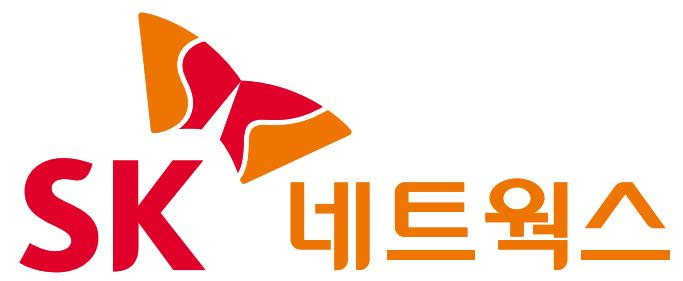

요약 :  SK 네트웍스 로고, 붉은색과 주황색이 조화를 이루며 브랜드 이름을 강조한 디자인.

1 : c:\workspaces\multimodal-rag\notebooks\data\figures\figure-1-2.jpg => 


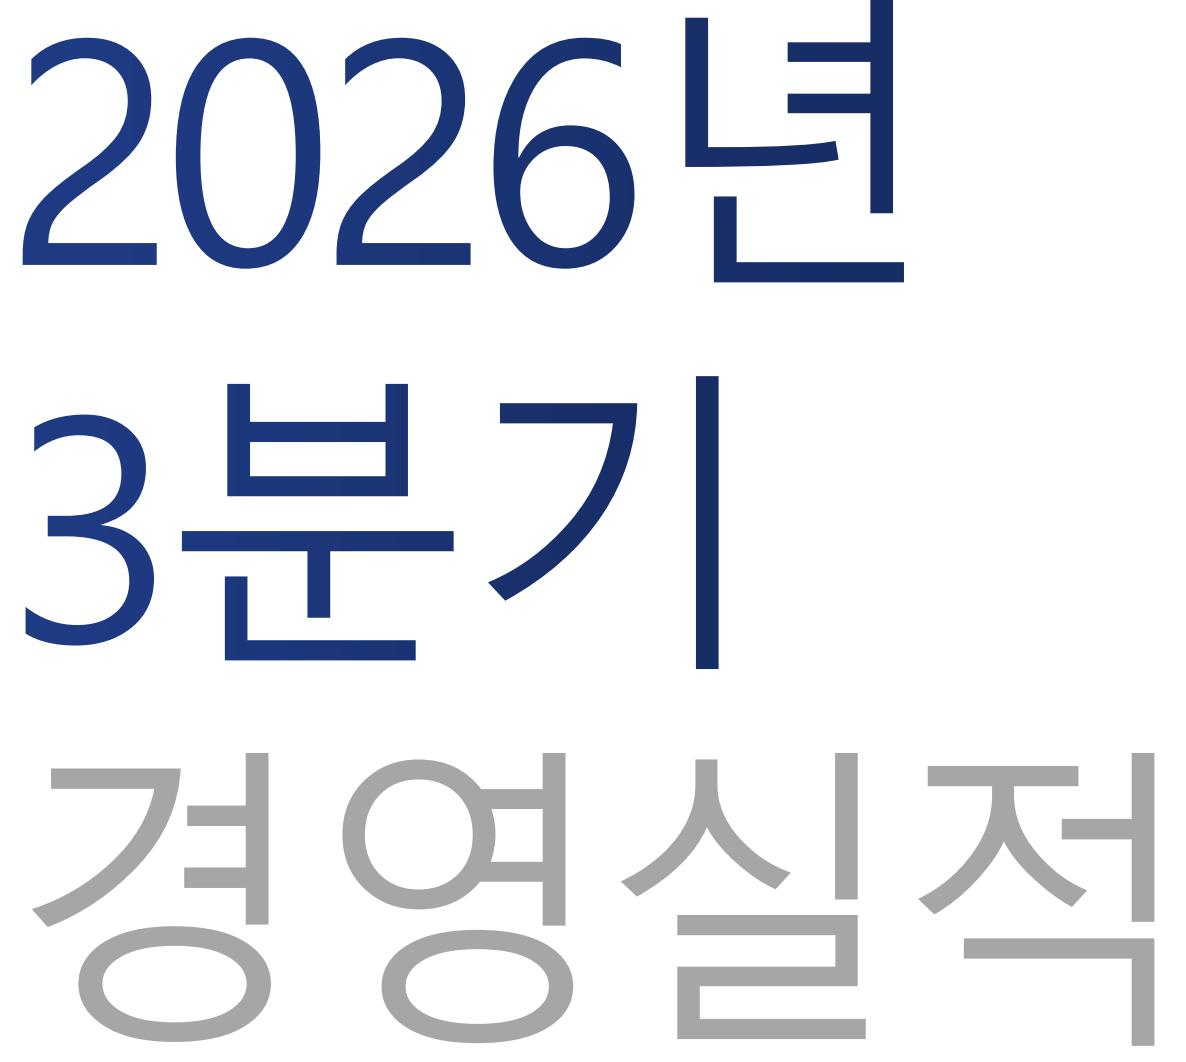

요약 :  2026년 3분기 경영실적 제목이 있는 이미지.

2 : c:\workspaces\multimodal-rag\notebooks\data\figures\figure-1-3.jpg => 


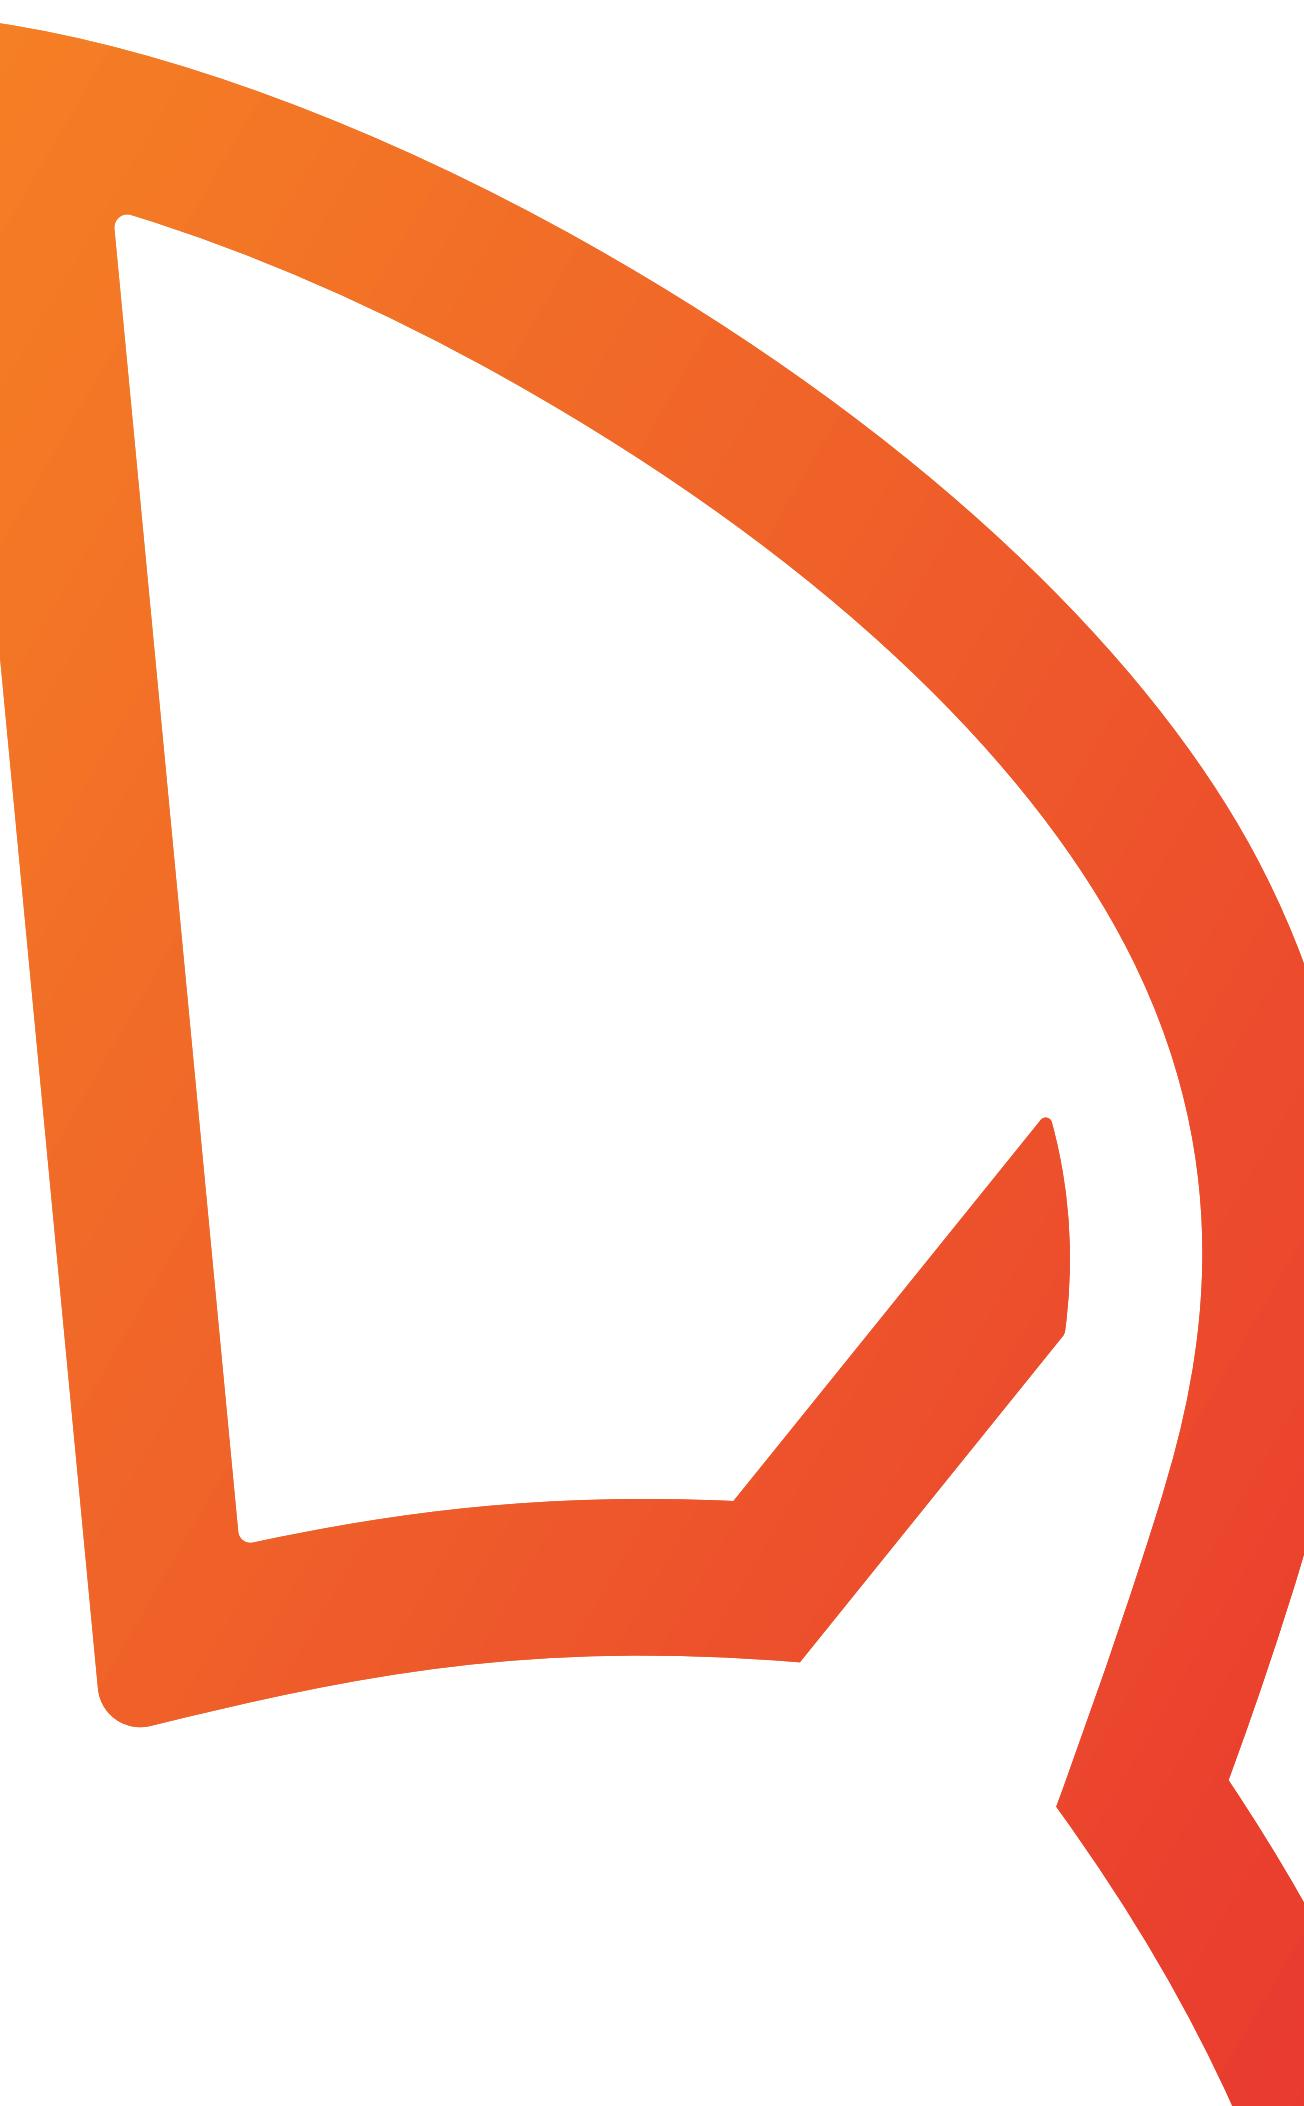

요약 :  주황색 그라데이션으로 이루어진 곡선과 선들이 있는 추상적인 디자인 이미지입니다. 주요 요소는 'D' 형태로 보이며, 깔끔하고 현대적인 느낌을 줍니다.



In [84]:
# ⌨️ 9-1. IPython.display 에서 Image, display 를 임포트합니다.
from IPython.display import Image, display
# ⌨️ 9-2. image_files 와 image_summaries 의 앞 3개를 zip + enumerate 로 반복하며
#        구분선, 번호와 파일 이름, 이미지(width=450), 요약문을 차례로 출력합니다.
for i, (image_file,image_summary) in enumerate(zip(image_files[:3], image_summaries[:3])):
    print("=" * 60)
    print(f"{i} : {image_file} => ")
    print("=" * 60)
    display(Image(filename=str(image_file), width=450))
    print("요약 : ", image_summary)
    print()

## 10. 토큰 사용량 측정

In [85]:
# ⌨️ 10-1. tiktoken 을 임포트하고 "gpt-4o-mini" 용 인코더(enc)를 가져옵니다.
import tiktoken
enc = tiktoken.encoding_for_model("gpt-4o-mini")
# ⌨️ 10-2. texts_2k_token 전체의 토큰 수 합 → input_tokens
input_tokens = sum(len(enc.encode(t)) for t in texts_2k_token)
# ⌨️ 10-3. text_summaries 전체의 토큰 수 합 → output_tokens
output_tokens = sum(len(enc.encode(s)) for s in text_summaries)
# ⌨️ 10-4. 입력 / 출력 / 합계 토큰(천 단위 콤마)과 요약한 이미지 수를 출력합니다.
print("텍스트 요약 토큰 사용량 (추정)")
print(f"  입력 : {input_tokens:,} 토큰")
print(f"  출력 : {output_tokens:,} 토큰")
print(f"  합계 : {input_tokens + output_tokens:,} 토큰")
print()
print("요약한 이미지 수:", len(image_summaries), "장")
print()
print("※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.")
print("※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.")

텍스트 요약 토큰 사용량 (추정)
  입력 : 2,496 토큰
  출력 : 642 토큰
  합계 : 3,138 토큰

요약한 이미지 수: 49 장

※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.
※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.


## 11. 저장

In [86]:
# ⌨️ 11-1. DATA_DIR / "processed" 를 output_dir 로 잡고 폴더를 만듭니다. (parents, exist_ok)
output_dir = DATA_DIR / "processed"
# ⌨️ 11-2. output_dir / "summaries.pkl" 에 아래 4개 키를 가진 딕셔너리를 pickle.dump 합니다.
#         text_summaries, table_summaries, image_summaries, img_base64_list
output_dir.mkdir(parents=True, exist_ok=True)

with open(output_dir / "SK_summaries.pkl", "wb") as f:
    pickle.dump(
        {
            "text_summaries": text_summaries,
            "table_summaries": table_summaries,
            "image_summaries": image_summaries,
            "img_base64_list": img_base64_list,
        },
        f,
    )

print("저장 완료:", output_dir / "SK_summaries.pkl")


# ⌨️ 11-3. 저장 경로를 출력합니다. (위 print 로 출력됨)

저장 완료: c:\workspaces\multimodal-rag\notebooks\data\processed\SK_summaries.pkl


# 3. 다중 벡터 검색기 + 최종 체인

## 0. 결과 복원

In [87]:
# ── 0. 결과 복원 ──────────────────────────────────────────
# 1) 필요한 모듈 import: os, re, time, uuid, pickle, pathlib.Path
# 2) python-dotenv 의 load_dotenv import
import os, re, time, uuid, pickle
from pathlib import Path
from dotenv import load_dotenv
# 3) .env 가 있는 폴더를 프로젝트 루트로 자동 탐색
#    - Path.cwd() 와 그 상위 폴더(parents)를 차례로 확인해 (p / ".env") 가 존재하는 첫 경로를 PROJECT_ROOT 로 지정
#    - 찾지 못하면 Path.cwd() 를 사용
#    - PROJECT_ROOT 출력 → c:\workspaces\multimodal-rag 이면 정상
# PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# PROJECT_ROOT / DATA_DIR 는 앞(1. 데이터 추출 경로 설정)에서 정의한 값을 그대로 사용합니다.
print(PROJECT_ROOT)
# 4) PROJECT_ROOT 의 .env 파일 로드 (load_dotenv)
# 5) OPENAI_API_KEY 가 없으면 ValueError 발생시키기

load_dotenv(PROJECT_ROOT / ".env")

if not os.getenv("OPENAI_API_KEY"):
    raise ValueError("OpenAI API 키가 없습니다. .env 파일을 확인하세요.")
# 6) processed 경로 = DATA_DIR / "processed"

processed = DATA_DIR / "processed"

# 7) 추출 결과 복원: processed/"SK_extracted.pkl" 을 pickle 로 읽기 ("rb")
#    - texts, tables, texts_2k_token 꺼내기
with open(processed / "SK_extracted.pkl", "rb") as f:
    d1 = pickle.load(f)
texts, tables, texts_2k_token = d1["texts"], d1["tables"], d1["texts_2k_token"]
# 8) 요약 결과 복원: processed/"SK_summaries.pkl" 을 pickle 로 읽기
#    - text_summaries, table_summaries, image_summaries, img_base64_list 꺼내기
with open(processed / "SK_summaries.pkl", "rb") as f:
    d2 = pickle.load(f)
text_summaries = d2["text_summaries"]
table_summaries = d2["table_summaries"]
image_summaries = d2["image_summaries"]
img_base64_list = d2["img_base64_list"]
# 9) "복원 완료" 와 함께 텍스트·표·이미지의 원본 수 / 요약 수 출력
print("복원 완료")
print(f"    텍스트  원본 {len(texts_2k_token):3d}건 / 요약 {len(text_summaries):3d}건")
print(f"    표      원본 {len(tables):3d}건 / 요약 {len(table_summaries):3d}건")
print(f"    이미지  원본 {len(img_base64_list):3d}건 / 요약 {len(image_summaries):3d}건")

c:\workspaces\multimodal-rag
복원 완료
    텍스트  원본   3건 / 요약   3건
    표      원본   6건 / 요약   6건
    이미지  원본  49건 / 요약  49건


## 1. 다중 벡터 검색기의 구조

> **비유:** **도서관의 색인 카드**입니다. 사서는 책을 다 읽고 찾지 않습니다. 요약이 적힌 **색인 카드로 검색**하고, 찾으면 **서가에서 진짜 책을 꺼내** 건네줍니다.

| 구성 요소 | 비유 | 들어가는 것 | 역할 |
| --- | --- | --- | --- |
| `vectorstore` (Chroma) | 색인 카드 서랍 | 요약문 임베딩 | **검색** |
| `docstore` (InMemoryStore) | 서가 | 원본 텍스트·표·Base64 이미지 | **전달** |
| `id_key` | 청구기호 | `doc_id` | 둘을 **연결** |

오늘 배우는 것의 핵심은 한 줄입니다.

> **요약과 원본에 같은 번호표를 붙인다.**

## 2. 검색기 만들기

In [88]:
# ── 2. 검색기 만들기 ──────────────────────────────────────
# langchain 1.x 에서 두 클래스의 위치가 바뀌었습니다.
# 어느 버전을 설치했든 동작하도록 두 경로를 모두 시도합니다. (try / except ImportError)

# 1) MultiVectorRetriever import
#    - langchain 1.x : langchain_classic.retrievers.multi_vector
#    - langchain 0.3 : langchain.retrievers.multi_vector
from langchain_classic.retrievers.multi_vector import MultiVectorRetriever
# 2) InMemoryStore import
#    - langchain 1.x : langchain_core.stores
#    - langchain 0.3 : langchain.storage
from langchain_core.stores import InMemoryStore
# 3) Chroma(langchain_chroma), OpenAIEmbeddings(langchain_openai) import
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings
# 4) 요약문이 들어갈 벡터 DB (= 색인 카드 서랍)
#    - collection_name="multimodal_rag"
#    - embedding_function = OpenAIEmbeddings(model="text-embedding-3-small")
vectorstore = Chroma(
    collection_name="multimodal_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small")
)
# 5) 원본이 들어갈 저장소 (= 서가) : InMemoryStore()
# 6) 연결 키(= 청구기호) : id_key = "doc_id"
store = InMemoryStore()
id_key = "doc_id"
# 7) MultiVectorRetriever(vectorstore=..., docstore=..., id_key=...) 생성
# 8) "검색기 생성 완료" 출력
retriever = MultiVectorRetriever(
    vectorstore=vectorstore,
    docstore=store,
    id_key=id_key,
)
print("검색기 생성완료!@!")

검색기 생성완료!@!


## 3. 요약과 원본을 같은 ID로 짝짓기

In [89]:
# ── 3. 요약과 원본을 같은 ID로 짝짓기 ─────────────────────
# 1) langchain_core.documents 의 Document import
from langchain_core.documents import Document as _Doc
# 2) add_documents(retriever, doc_summaries, doc_contents) 함수 정의
#    """요약본은 벡터 DB에, 원본은 docstore에 '같은 id'로 저장합니다."""
#    - 원본 개수만큼 uuid4 로 doc_ids 생성 (문자열로 변환)
#    - 요약문마다 Document(page_content=요약, metadata={id_key: doc_ids[i]}) 생성
def add_documents(retriever, doc_summaries, doc_contents):
    """요약본은 벡터 DB에, 원본은 docstore에 '같은 id'로 저장합니다."""
    doc_ids = [str(uuid.uuid4()) for _ in doc_contents]

    summary_docs = [
        _Doc(page_content = s, metadata={id_key: doc_ids[i]})
        for i, s in enumerate(doc_summaries)
    ]
#    - TODO 1: 요약본은 어디에 넣을까요? (vectorstore / docstore)
#      → retriever.vectorstore.add_documents(...)
    retriever.vectorstore.add_documents(summary_docs)
#    - TODO 2: 원본은 어디에 넣을까요?
#      → retriever.docstore.mset(list(zip(doc_ids, doc_contents)))
    retriever.docstore.mset(list(zip(doc_ids, doc_contents)))
# 3) 데이터가 있을 때만 각각 저장
#    - text_summaries  ↔ texts_2k_token
#    - table_summaries ↔ tables
#    - image_summaries ↔ img_base64_list
if text_summaries:
    add_documents(retriever, text_summaries, texts_2k_token)
if table_summaries:
    add_documents(retriever, table_summaries, tables)
if image_summaries:
    add_documents(retriever, image_summaries, img_base64_list)
# 4) "색인 완료" 와 벡터 DB에 저장된 요약 수 출력 (vectorstore.get()["ids"] 의 길이)
# ⚠️ 이 셀을 두 번 실행하면 데이터가 중복됩니다.

print("색인 완료")
print(" 벡터 DB에 저장된 요약 수: ", vectorstore._collection.count())

색인 완료
 벡터 DB에 저장된 요약 수:  174


## 4. 검색 테스트 — 요약으로 찾고 원본을 받는다


In [90]:
# ── 4. 검색 테스트 ────────────────────────────────────────
# TODO 3: 그래프나 표를 봐야만 답할 수 있는 질문을 query 에 적으세요
query = "2026년 3분기 말 기준 SK네트웍스의 주주 구성에서 특수관계인, 개인, 외국인, 기관, 자사주의 지분율은 각각 얼마인가요?"
# 1) retriever.invoke(query) 결과를 found 에 저장
# 2) 검색된 원본 수 출력
found = retriever.invoke(query)
print("검색된 원본 수 : ", len(found))
print()
# 3) found 를 순회하며
#    - content = doc.page_content (Document 가 아니면 doc 그대로)
#    - 정규식 "^[A-Za-z0-9+/]{100,}={0,2}$" 에 맞으면 "이미지(Base64)", 아니면 "텍스트/표"
#    - 종류, 길이, 앞 120자(줄바꿈 제거) 출력

for i, doc in enumerate(found):
    content = doc.page_content if hasattr(doc, "page_content") else doc
    is_image = bool(re.match("^[A-Za-z0-9+/]{100,}={0,2}$", content))
    kind = "이미지(Base64)" if is_image else "텍스트/표"
    print(f"[{i}] {kind} — 길이 {len(content):,}자")
    print("   ", content[:120].replace("\n", " "), "...")
    print()

검색된 원본 수 :  2

[0] 이미지(Base64) — 길이 165,008자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...

[1] 이미지(Base64) — 길이 194,372자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...



## 5. 검색 결과를 텍스트와 이미지로 분리

In [91]:
# ── 5. 검색 결과를 텍스트와 이미지로 분리 ─────────────────
# 1) langchain_core.documents 의 Document import
from langchain_core.documents import Document
# 2) split_image_text_types(docs) 함수 정의
#    """검색 결과를 Base64 이미지와 텍스트로 나눕니다."""
def split_image_text_types(docs):
    """검색 결과를 Base64 이미지와 텍스트로 나눕니다."""
#    - b64_images, texts_out 빈 리스트 준비
    b64_images = []
    texts_out = []
#    - Document 면 page_content 를 꺼내 문자열로 만들기
    for doc in docs:
        content = doc.page_content if isinstance(doc, Document) else doc
        if re.match("^[A-Za-z0-9+/]{100,}={0,2}$", content):
            b64_images.append(content)
        else:
            texts_out.append(content)

    return {"images": b64_images,"texts": texts_out}
#    - Base64 문자열은 영문/숫자/+/= 만으로 길게 이어집니다
#      → 정규식 "^[A-Za-z0-9+/]{100,}={0,2}$" 매칭 시 이미지, 아니면 텍스트
#    - {"images": b64_images, "texts": texts_out} 반환

# 3) 앞서 검색한 결과(found)로 동작 확인 → 이미지 / 텍스트 건수 출력
split = split_image_text_types(found)
print("이미지:", len(split["images"]), "건")
print("표", len(split["texts"]), "건")

이미지: 2 건
표 0 건


## 6. 최종 멀티모달 체인 만들기

In [92]:
# ── 6. 최종 멀티모달 체인 만들기 ──────────────────────────
# 1) import
#    - HumanMessage (langchain_core.messages)
#    - StrOutputParser (langchain_core.output_parsers)
#    - ChatPromptTemplate (langchain_core.prompts)
#    - RunnableLambda, RunnablePassthrough (langchain_core.runnables)
#    - ChatOpenAI (langchain_openai)
from langchain_core.messages import HumanMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
from langchain_openai import ChatOpenAI
# 2) img_prompt_func(data_dict) 함수 정의
#    """검색된 원본을 멀티모달 LLM이 읽을 형태로 조립합니다."""
#    - messages 빈 리스트 준비
#    - 1) 이미지를 먼저 넣습니다 (모델이 그림을 먼저 보게)
#         data_dict["context"]["images"] 마다 {"type": "image_url", "image_url": {"url": ...}} 추가
#         TODO 4: Base64 앞에 붙일 접두사를 완성하세요 (data:image/jpeg;base64,)
#    - 2) 텍스트 컨텍스트와 질문을 넣습니다
#         texts 를 줄바꿈으로 합치고 {"type": "text", "text": ...} 추가
#         지시문: "아래 자료를 근거로 질문에 한국어로 답하세요. 자료에 없는 내용은 모른다고 답하세요."
#         + 질문(data_dict["question"]) + 참고 텍스트
#    - [HumanMessage(content=messages)] 반환
def img_prompt_func(data_dict):
    """검색된 원본을 멀티모달 LLM이 읽을 형태로 조립합니다."""
    messages = []
    for image in data_dict["context"]["images"]:
        messages.append({
            "type": "image_url",
            # TODO 4: Base64 앞에 붙일 접두사를 완성하세요
            "image_url": {"url": f"data:image/jpeg;base64,{image}"},
        })

    formatted_texts = "\n".join(data_dict["context"]["texts"])
    messages.append({
        "type": "text",
        "text": (
            "아래 자료를 근거로 질문에 한국어로 답하세요.\n"
            "자료에 없는 내용은 모른다고 답하세요.\n\n"
            f"질문: {data_dict['question']}\n\n"
            f"참고 텍스트:\n{formatted_texts}"
        ),
    })
    return [HumanMessage(content=messages)]
# 3) 모델: ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)
model = ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)
# 4) 체인 조립 (LCEL)
#    {"context": retriever | RunnableLambda(split_image_text_types),
#     "question": RunnablePassthrough()}
#    | RunnableLambda(img_prompt_func)
#    | TODO 5: 멀티모달 LLM 변수
#    | StrOutputParser()
chain = (
    {
        "context": retriever | RunnableLambda(split_image_text_types),
        "question": RunnablePassthrough(),
    }
    | RunnableLambda(img_prompt_func)
    | model                     # TODO 5: 답변을 생성할 모델
    | StrOutputParser()
)
# 5) "최종 체인 조립 완료" 출력
print("최종 체인 조립 완료")

최종 체인 조립 완료


## 7. 질의 실행

In [93]:
# ── 7. 질의 실행 ──────────────────────────────────────────
# 1) 시작 시간 기록 (time.time())
# 2) chain.invoke(query) 결과를 answer 에 저장
# 3) 소요 시간, 질문(Q), 구분선, 답변 출력

start = time.time()
answer = chain.invoke(query)

print(f"답변 생성 — {time.time() - start:.1f}초\n")
print("Q:", query)
print("-" * 70)
print(answer)

답변 생성 — 2.8초

Q: 2026년 3분기 말 기준 SK네트웍스의 주주 구성에서 특수관계인, 개인, 외국인, 기관, 자사주의 지분율은 각각 얼마인가요?
----------------------------------------------------------------------
2026년 3분기 말 기준 SK네트웍스의 주주 구성에서 지분율은 다음과 같습니다:

- 특수관계인: 49.0%
- 개인: 24.7%
- 외국인: 14.2%
- 기관: 8.8%
- 자사주: 3.3%


## 8. Before / After 비교 (가장 중요)

In [94]:
# ── 8-1. 비교용 텍스트 전용 RAG ────────────────────────────
# 이미지와 표를 뺀 것 말고는 모든 조건이 같아야 합니다.

# 1) 텍스트만 들어간 벡터 DB 생성
#    - Chroma(collection_name="text_only_rag", embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"))
#    - texts_2k_token 을 add_texts 로 저장
#    - as_retriever(search_kwargs={"k": 4}) 로 검색기 생성
text_only_store = Chroma(
    collection_name="text_only_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small")
)
text_only_store.add_texts(texts_2k_token)
text_only_retriever = text_only_store.as_retriever(search_kwargs={"k": 4})
# 2) 프롬프트: ChatPromptTemplate.from_template
#    - 멀티모달 체인과 같은 지시문 + {question} + {context}
text_only_prompt = ChatPromptTemplate.from_template(
    "아래 자료를 근거로 질문에 한국어로 답하세요.\n"
    "자료에 없는 내용은 모른다고 답하세요.\n\n"
    "질문: {question}\n\n참고 텍스트:\n{context}"
)
# 3) 체인 조립
#    {"context": 검색기 | (문서들의 page_content 를 줄바꿈으로 합치는 함수),
#     "question": RunnablePassthrough()}
#    | 프롬프트 | model | StrOutputParser()
text_only_chain= (
    {
        "context": text_only_retriever | (lambda docs: "\n".join(d.page_content for d in docs)),
        "question": RunnablePassthrough(),
    }
    | text_only_prompt
    | model
    | StrOutputParser()
)
# 4) "비교용 텍스트 전용 RAG 준비 완료" 출력
print("비교용 텍스트 전용 RAG 준비 완료")

비교용 텍스트 전용 RAG 준비 완료


In [95]:
# ── 8-2. Before / After 출력 ───────────────────────────────
# 1) 구분선과 질문 출력
print("=" * 70)
print("질문:", query)
print("=" * 70)
print()
# 2) [BEFORE] 텍스트 전용 RAG
#    - text_only_chain.invoke(query) 결과를 before 에 저장 후 출력

print("[BEFORE] 텍스트 전용 RAG")
print("-" * 70)
before = text_only_chain.invoke(query)
print(before)
print()
# 3) [AFTER] 멀티모달 RAG
#    - chain.invoke(query) 결과를 after 에 저장 후 출력
print("[AFTER] 멀티모달 RAG")
print("-" * 70)
after = chain.invoke(query)
print(after)
print()
# 4) "이 출력 전체를 캡처해 README.md에 넣으세요." 안내 출력
print("=" * 70)
print("이 출력 전체를 캡처해 README.md에 넣으세요.")
print("=" * 70)

질문: 2026년 3분기 말 기준 SK네트웍스의 주주 구성에서 특수관계인, 개인, 외국인, 기관, 자사주의 지분율은 각각 얼마인가요?

[BEFORE] 텍스트 전용 RAG
----------------------------------------------------------------------
자료에 주주 구성에 대한 구체적인 지분율 정보는 포함되어 있지 않습니다. 따라서 2026년 3분기 말 기준 SK네트웍스의 주주 구성에서 특수관계인, 개인, 외국인, 기관, 자사주의 지분율은 알 수 없습니다.

[AFTER] 멀티모달 RAG
----------------------------------------------------------------------
2026년 3분기 말 기준 SK네트웍스의 주주 구성에서 지분율은 다음과 같습니다:

- 특수관계인: 49.0%
- 개인: 24.7%
- 외국인: 14.2%
- 기관: 8.8%
- 자사주: 3.3%

이 출력 전체를 캡처해 README.md에 넣으세요.


## 9. 추가 질의 5개 — Before / After 결과표

SK_networks.pdf 의 **차트 이미지 안에만 있는 수치**를 묻는 질문 5개입니다.
정답 수치가 추출된 텍스트·표에 없기 때문에, 텍스트 전용 RAG(Before)는 답하기 어렵고
이미지를 함께 보는 멀티모달 RAG(After)만 답할 수 있어야 합니다.
`expected` 는 PDF 원본 차트 이미지에서 직접 확인한 값이며, 채점 참고용입니다.

In [96]:
# ── 9. 추가 질의 5개 실행 ─────────────────────────────────
queries = [
    {
        "q": "2026년 3분기 말 기준 SK네트웍스의 외국인 지분율과 자사주 지분율은 각각 몇 %인가요?",
        "expected": "외국인 14.2%, 자사주 3.3%",
        "source": "p.4 주주구성 도넛 차트 (이미지 전용)",
    },
    {
        "q": "워커힐 호텔의 객실, F&B, 호텔 기타 부문의 2026년 3분기 매출은 각각 몇 억 원인가요?",
        "expected": "객실 198억원, F&B 375억원, 호텔 기타 55억원",
        "source": "p.11 호텔 주요 사업별 매출 차트 (이미지 전용)",
    },
    {
        "q": "워커힐 호텔의 2025년 3분기 객실 평균 점유율은 몇 %였나요?",
        "expected": "80.3%",
        "source": "p.11 객실 평균 점유율 차트 (이미지 전용)",
    },
    {
        "q": "SK인텔릭스(렌탈 사업)의 분기별 매출 중 가장 높았던 분기는 언제이고, 금액은 얼마인가요?",
        "expected": "2026년 1분기(’26.1Q), 2,218억원",
        "source": "p.9 SK인텔릭스 분기별 매출 차트 (이미지 전용)",
    },
    {
        "q": "SK인텔릭스(렌탈 사업)의 2025년 4분기 매출과 영업이익은 각각 얼마인가요?",
        "expected": "매출 2,035억원, 영업이익 12억원",
        "source": "p.9 SK인텔릭스 분기별 매출·영업이익 차트 (이미지 전용)",
    },
]

results = []
for i, item in enumerate(queries, 1):
    print("=" * 70)
    print(f"[Q{i}] {item['q']}")
    print(f"      (출처: {item['source']} / 정답: {item['expected']})")
    print("=" * 70)

    before = text_only_chain.invoke(item["q"])
    after = chain.invoke(item["q"])

    print("[BEFORE] 텍스트 전용 RAG")
    print(before)
    print()
    print("[AFTER] 멀티모달 RAG")
    print(after)
    print()

    results.append({**item, "before": before, "after": after})

print("완료:", len(results), "개 질의")

[Q1] 최근 5개 분기(2025년 3분기~2026년 3분기) 중 전사 매출이 가장 낮았던 분기는 언제이고, 금액은 얼마인가요?
      (출처: p.7 매출 막대 차트 / 정답: 2026년 2분기(’26.2Q), 14,445억원)
[BEFORE] 텍스트 전용 RAG
최근 5개 분기(2025년 3분기~2026년 3분기) 중 전사 매출이 가장 낮았던 분기는 2025년 4분기이며, 금액은 12,165억 원입니다.

[AFTER] 멀티모달 RAG
자료에 없는 내용은 모른다고 답합니다.

[Q2] 최근 5개 분기 중 전사 영업이익이 가장 컸던 분기는 언제이고, 금액은 얼마인가요?
      (출처: p.7 영업이익 막대 차트 / 정답: 2026년 1분기(’26.1Q), 334억원)
[BEFORE] 텍스트 전용 RAG
자료에 영업이익에 대한 구체적인 금액이나 분기별 실적이 명시되어 있지 않아서, 최근 5개 분기 중 전사 영업이익이 가장 컸던 분기와 그 금액에 대한 정보를 제공할 수 없습니다.

[AFTER] 멀티모달 RAG
최근 5개 분기 중 전사 영업이익이 가장 컸던 분기는 2026년 2분기이며, 금액은 2,015억 원입니다.

[Q3] SK인텔릭스의 글로벌 렌탈 누적 계정 수가 가장 적었던 분기는 언제이고, 몇 만 계정인가요?
      (출처: p.9 글로벌 렌탈 계정 막대 차트 / 정답: 2025년 4분기(’25.4Q), 22.8만 계정)
[BEFORE] 텍스트 전용 RAG
자료에 따르면 SK인텔릭스의 글로벌 렌탈 누적 계정 수가 가장 적었던 분기는 2026년 3분기이며, 그 수는 22만 계정입니다.

[AFTER] 멀티모달 RAG
자료에 따르면 SK인텔릭스의 글로벌 렌탈 누적 계정 수가 가장 적었던 분기는 2026년 3분기이며, 계정 수는 44만 계정입니다.

[Q4] 워커힐 호텔의 객실 평균 점유율이 가장 낮았던 분기는 언제이고, 점유율은 몇 %인가요?
      (출처: p.11 객실 평균 점유율 막대 차트 / 정답: 2026년 1분기(’26.1Q), 6

### 결과표 저장

실행 결과를 `results.md` 로 저장합니다. README.md 에 붙여 넣어 제출하세요.

In [97]:
# ── 결과표를 마크다운으로 저장 ────────────────────────────
def _cell(s):
    return str(s).replace("|", "\\|").replace("\n", "<br>")

rows = ["| # | 질문 | 정답(원문) | Before (텍스트 전용) | After (멀티모달) |",
        "|---|---|---|---|---|"]
for i, r in enumerate(results, 1):
    rows.append(f"| {i} | {_cell(r['q'])} | {_cell(r['expected'])} | {_cell(r['before'])} | {_cell(r['after'])} |")

report = "\n".join(rows)
(PROJECT_ROOT / "notebooks" / "results.md").write_text(report, encoding="utf-8")
print(report)
print("\n저장 완료:", PROJECT_ROOT / "notebooks" / "results.md")

| # | 질문 | 정답(원문) | Before (텍스트 전용) | After (멀티모달) |
|---|---|---|---|---|
| 1 | 최근 5개 분기(2025년 3분기~2026년 3분기) 중 전사 매출이 가장 낮았던 분기는 언제이고, 금액은 얼마인가요? | 2026년 2분기(’26.2Q), 14,445억원 | 최근 5개 분기(2025년 3분기~2026년 3분기) 중 전사 매출이 가장 낮았던 분기는 2025년 4분기이며, 금액은 12,165억 원입니다. | 자료에 없는 내용은 모른다고 답합니다. |
| 2 | 최근 5개 분기 중 전사 영업이익이 가장 컸던 분기는 언제이고, 금액은 얼마인가요? | 2026년 1분기(’26.1Q), 334억원 | 자료에 영업이익에 대한 구체적인 금액이나 분기별 실적이 명시되어 있지 않아서, 최근 5개 분기 중 전사 영업이익이 가장 컸던 분기와 그 금액에 대한 정보를 제공할 수 없습니다. | 최근 5개 분기 중 전사 영업이익이 가장 컸던 분기는 2026년 2분기이며, 금액은 2,015억 원입니다. |
| 3 | SK인텔릭스의 글로벌 렌탈 누적 계정 수가 가장 적었던 분기는 언제이고, 몇 만 계정인가요? | 2025년 4분기(’25.4Q), 22.8만 계정 | 자료에 따르면 SK인텔릭스의 글로벌 렌탈 누적 계정 수가 가장 적었던 분기는 2026년 3분기이며, 그 수는 22만 계정입니다. | 자료에 따르면 SK인텔릭스의 글로벌 렌탈 누적 계정 수가 가장 적었던 분기는 2026년 3분기이며, 계정 수는 44만 계정입니다. |
| 4 | 워커힐 호텔의 객실 평균 점유율이 가장 낮았던 분기는 언제이고, 점유율은 몇 %인가요? | 2026년 1분기(’26.1Q), 60.3% | 워커힐 호텔의 객실 평균 점유율이 가장 낮았던 분기는 2025년 4분기(25.4Q)이며, 점유율은 58%입니다. | 워커힐 호텔의 객실 평균 점유율이 가장 낮았던 분기는 26.1Q이며, 점유율은 60.3%입니다. |
| 5 | 워커힐 호텔의 F&B 매출은 20